In [1]:
# 🛠 Prototype only: a NumPy stand-in for the zero_shot_probabilities you wrote in Part 3.
import numpy as np

def zero_shot_probabilities(logits, kind):
    logits = np.asarray(logits, dtype=float)
    if kind == "softmax":
        e = np.exp(logits - logits.max(-1, keepdims=True))
        return e / e.sum(-1, keepdims=True)
    return 1 / (1 + np.exp(-logits))

> 🛠 **Prototype note (issue 245, throwaway; not part of any page).** This mocks the chapter that would follow "What we did not show" at the end of part 4️⃣ of
> [12.1] *CLIP and SigLIP from Scratch*, just before ☆ Bonus. Every revealed number comes from 12.1's own runs: the Part 2 expected output and the
> Bonus text. Nothing new was run. Notes marked 🛠 are for you, not for learners. The open choices are listed in `README.md`.
>
> It would also add one entry to *Content & Learning Objectives*, between 4️⃣ and ☆ Bonus:
>
> > ### 🎯 Held-out Quiz
> >
> > Four experiments we ran on your tiny CLIP and didn't show you. Each changes one thing in a run you made. You'll predict each result and write down
> > why, then see what really happened and what a good mental model would have said.
> >
> > > ##### Learning Objectives
> > >
> > > - Predict the result of a change to a training run from results you've already measured
> > > - Name the result your prediction rests on, and notice when a paper's claim and your own runs disagree
> > > - Find the place where your picture of the softmax and sigmoid losses breaks

---

```
=== NEW CHAPTER ===
```

# 🎯 Held-out Quiz

You've trained the tiny CLIP with both losses at one batch size and one learning rate. You've seen the shuffled-caption controls sit at losses of 4.159 and 5.151,
and you've watched the sigmoid loss need its $-10$ bias. We trained the same model on the same data a dozen more times, changing one thing each time, and we haven't
shown you any of those runs. Before you see them, predict them.

This is how Stanford's CS 312 *[Deep Learning Alchemy](https://deep-learning-alchemy.github.io/)* tests understanding: if you understand a system, you can say
what it will do in a setting you haven't tried. A wrong answer here isn't a failure. It's the most useful thing that can happen in this lesson, because it shows
you exactly which part of your picture is off.

**How it works.**

1. Each question shows its change as a diff against a call you ran in this lesson.
2. Write your answers, and one sentence of reasoning for each, in the answer cell. The reasoning should name a result from this lesson. Don't run any new
   experiments first.
3. Run `quiz.score(my_answers)`, then open the **Reveal** dropdowns. Each has the real numbers and what a good mental model would have said.

**Difficulty** says how far a question takes you from what you ran:

- **Easy** means something you built, used on a case it was designed for.
- **Medium** means one knob turned beyond the range you ran.
- **Hard** means a regime you never saw, or a number rather than a direction.

**Scoring.** An interval question gives full points for the right interval and half for a neighbouring one. A ranking gives one point for every pair of runs you
put in the right order. Write `=` when you think two runs land within 0.05 of each other. There are 20 points in total. The score is for you: it isn't saved or
sent anywhere. Expect to get around half.

> ```yaml
> Importance: 🔵🔵🔵🔵⚪
>
> You should spend up to 25-30 minutes on this quiz.
> ```

**The baseline.** Q2, Q3 and Q4 change this call from Part 2, which you ran once with each loss:

In [ ]:
m = fresh_model(siglip=(loss_name == "siglip"))
hist = train_tiny_clip(m, train_images, CAPTION_IDS, train_classes, loss_name, "paired", steps=2000, batch_size=64, lr=5e-4, seed=0)

It gave an image-to-text R@1 of 0.942 with the CLIP loss and 0.958 with the SigLIP loss (0.71 and 0.79 on held-out combinations). Chance is 1/120 = 0.008.

In [2]:
import quiz_12_1 as quiz

## Q1. More candidates, same logits &nbsp;·&nbsp; Easy &nbsp;·&nbsp; 4 points

**From the lesson.** In Part 3 you wrote `zero_shot_probabilities(logits, kind)`. It turns a logit matrix into match probabilities, with a softmax over each row for
CLIP or an elementwise sigmoid for SigLIP.

**This question changes.** Four images were scored against three candidate captions, c0–c2. We add two more captions, c3 and c4, and recompute. The logits of the
original pairs don't change. The correct caption for each image is in bold.

```diff
- probs = zero_shot_probabilities(logits[:, :3], kind)   # 3 candidate captions
+ probs = zero_shot_probabilities(logits, kind)          # 5: two new captions added
```

|         |    c0     |    c1    |    c2     | c3 (new) | c4 (new) |
| ------- | :-------: | :------: | :-------: | :------: | :------: |
| image 0 |   −1.25   | **0.00** |   1.25    |  −1.75   |  −0.50   |
| image 1 |   0.50    |   1.75   | **−1.25** |   0.00   |   1.25   |
| image 2 | **−2.00** |  −0.75   |   0.50    |   1.75   |  −1.25   |
| image 3 |   −0.25   | **1.00** |   −2.00   |  −0.75   |   0.50   |

**(a)** For each kind (`"softmax"`, `"sigmoid"`), what happens to the probability of each image's correct caption? It **falls** for every image, is **unchanged**
for every image, **rises** for every image, or **depends** on the image.

**(b)** The mean change in the *softmax* probability of the correct caption, over the four images, is in:

| a | b | c | d | e |
|---|---|---|---|---|
| 0 to −2 points | −2 to −5 points | −5 to −15 points | −15 to −30 points | below −30 points |

> 🛠 This is the old blind CLIP companion (`mastery_hub/units/clip_prediction`, 1,316 lines of protocol, seals and attempt budgets, whose answer was never
> revealed) rewritten as one quiz question. It uses the same fixed logits and the same metric.


## Q2. Turning up the learning rate &nbsp;·&nbsp; Medium &nbsp;·&nbsp; 6 points

**From the lesson.** At the learning rate you used ($5 \times 10^{-4}$), both losses reach an R@1 of about 0.95.

**This question changes.** It changes only the peak learning rate, to 4× and 10× the one you used. The schedule, 2,000 steps and batch size 64 stay the same. There
are two seeds per run.

```diff
- hist = train_tiny_clip(m, train_images, CAPTION_IDS, train_classes, loss_name, "paired", steps=2000, batch_size=64, lr=5e-4, seed=0)
+ hist = train_tiny_clip(m, train_images, CAPTION_IDS, train_classes, loss_name, "paired", steps=2000, batch_size=64, lr=lr, seed=seed)
+ # A: loss_name="clip",   lr=2e-3        B: loss_name="clip",   lr=5e-3
+ # C: loss_name="siglip", lr=2e-3        D: loss_name="siglip", lr=5e-3
+ # two seeds each; we compare the mean final image-to-text R@1
```

**Rank A, B, C and D** by mean final R@1, lowest first, for example `C < A = D < B`. Use `=` for runs within 0.05 of each other.


## Q3. Smaller batches &nbsp;·&nbsp; Medium &nbsp;·&nbsp; 5 points

**From the lesson.** At batch size 64 the two losses were level: 0.942 for CLIP and 0.958 for SigLIP. The SigLIP paper (Zhai et al., 2023) reports that the sigmoid
loss is at least on par with softmax, and does particularly well at small batch sizes.

**This question changes.** The batch size drops from 64 to 16 for both losses. Everything else is as in Part 2, including the bias initialisation of $-10$. There are
three seeds per loss.

```diff
- ..., steps=2000, batch_size=64, lr=5e-4, seed=0)
+ ..., steps=2000, batch_size=16, lr=5e-4, seed=seed)   # three seeds per loss
```

Let $\Delta$ = mean R@1 (SigLIP) − mean R@1 (CLIP). $\Delta$ is in:

| a | b | c | d | e |
|---|---|---|---|---|
| below −0.20 | −0.20 to −0.05 | −0.05 to +0.05 | +0.05 to +0.20 | above +0.20 |


## Q4. Where does the broken run end up? &nbsp;·&nbsp; Hard &nbsp;·&nbsp; 5 points

**This question changes.** Take run D from Q2: the SigLIP loss at 10× the learning rate. What is its final training loss, the mean of the last 50 steps?

| a | b | c | d | e |
|---|---|---|---|---|
| below 0.5 | 0.5 to 2 | 2 to 4.5 | 4.5 to 5.5 | above 5.5, or the loss becomes NaN |


## Your answers

In [3]:
# 🛠 Prototype: filled with an example learner's answers.
# Fill in every answer before you open any Reveal below.
my_answers = {
    "Q1a_softmax": "falls",  # "falls", "unchanged", "rises" or "depends"
    "Q1a_sigmoid": "unchanged",
    "Q1b": "b",  # "a" to "e"
    "Q2": "D = C < A = B",  # e.g. "C < A = D < B"
    "Q3": "d",  # "a" to "e"
    "Q4": "e",  # "a" to "e"
}
my_reasons = {  # one sentence each: which result from this lesson are you relying on?
    "Q1": "",
    "Q2": "D = C < A = B",
    "Q3": "d",
    "Q4": "e",
}

In [4]:
quiz.score(my_answers)

question     your answer      answer           points
Q1a_softmax  falls            falls            1 / 1
Q1a_sigmoid  unchanged        unchanged        1 / 1
Q1b          b                c                1 / 2
Q2           D = C < A = B    D < C < A = B    5 / 6
Q3           d                a                0 / 5
Q4           e                d                2.5 / 5
total                                          10.5 / 20


> 🛠 In the prototype notebook this cell is run with an example learner's answers, one who trusted the SigLIP paper on Q3 and expected Q4 to diverge:
>
> ```
> question     your answer      answer           points
> Q1a_softmax  falls            falls            1 / 1
> Q1a_sigmoid  unchanged        unchanged        1 / 1
> Q1b          b                c                1 / 2
> Q2           D = C < A = B    D < C < A = B    5 / 6
> Q3           d                a                0 / 5
> Q4           e                d                2.5 / 5
> total                                          10.5 / 20
> ```


## Reveal

Q1's reveal runs your own `zero_shot_probabilities` from Part 3, so it is live and instant:

In [5]:
quiz.reveal_q1(zero_shot_probabilities)

softmax: probability of the correct caption, 3 candidates -> 5 candidates
  image 0: 0.209 -> 0.180   ( -2.9 points)
  image 1: 0.037 -> 0.024   ( -1.4 points)
  image 2: 0.060 -> 0.016   ( -4.4 points)
  image 3: 0.748 -> 0.472   (-27.6 points)
  mean change: -9.1 percentage points

sigmoid: probability of the correct caption, 3 candidates -> 5 candidates
  image 0: 0.500 -> 0.500   ( +0.0 points)
  image 1: 0.223 -> 0.223   ( +0.0 points)
  image 2: 0.119 -> 0.119   ( +0.0 points)
  image 3: 0.731 -> 0.731   ( +0.0 points)
  mean change: +0.0 percentage points



<details>
<summary>Reveal - Q1: more candidates, same logits</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">softmax: probability of the correct caption, 3 candidates -> 5 candidates
  image 0: 0.209 -> 0.180   ( -2.9 points)
  image 1: 0.037 -> 0.024   ( -1.4 points)
  image 2: 0.060 -> 0.016   ( -4.4 points)
  image 3: 0.748 -> 0.472   (-27.6 points)
  mean change: -9.1 percentage points

sigmoid: probability of the correct caption, 3 candidates -> 5 candidates
  image 0: 0.500 -> 0.500   ( +0.0 points)
  image 1: 0.223 -> 0.223   ( +0.0 points)
  image 2: 0.119 -> 0.119   ( +0.0 points)
  image 3: 0.731 -> 0.731   ( +0.0 points)
  mean change: +0.0 percentage points</pre>

**Answer:** (a) softmax **falls** for every image and sigmoid is **unchanged**; (b) **c**, −9.1 points.

**The mental model.** A softmax row is a competition for a fixed budget of 1. A new candidate always takes some of that budget, however weak it is. The correct caption's
probability is multiplied by $Z_\text{old}/Z_\text{new}$, so it always falls. How far it falls in *points* depends on how much it had and how strong the newcomers
are. Image 3 had 0.75 and meets a newcomer (0.50) close to its own logit, so it loses 28 points. Image 2 meets the strongest newcomer in the table (1.75), but it only
had 0.06 to lose. A sigmoid scores every pair on its own, so adding columns can't touch it.

This is the Part 3 result about abstaining, seen from the other side. A SigLIP score means the same thing however many captions you show the model. A CLIP score means
"better than the other captions on this list". If you got (a) wrong, re-read the part of Part 3 where both models are shown captions that don't fit the image.

</details>

<details>
<summary>Reveal - Q2: turning up the learning rate</summary>

| run | loss | learning rate | final R@1, mean of 2 seeds (each seed) |
| --- | --- | --- | --- |
| A | CLIP | 2e-3 | 0.965 (0.96, 0.97) |
| B | CLIP | 5e-3 | 0.97 (0.96, 0.98) |
| C | SigLIP | 2e-3 | 0.69 (0.80, 0.58) |
| D | SigLIP | 5e-3 | 0.008 (0.008, 0.008), which is chance |

**Answer:** `D < C < A = B`.

**The mental model.** The CLIP loss barely noticed a 10× learning rate. The sigmoid loss got worse at 4× and failed completely at 10×. The likely reason is one you met in Part 1:
softmax is invariant to adding the same number to every logit in a row, so a large step that moves a whole row together costs nothing. The sigmoid loss has no such
slack. Every pair is pushed on its own, and 63 of every 64 pairs in a batch are negatives. Q4 shows where a big step can then end up.

Also notice the two seeds at 2e-3: 0.80 and 0.58. Close to an instability, seeds disagree, and a single seed would have told you either story.

</details>

<details>
<summary>Reveal - Q3: smaller batches</summary>

| loss | batch 16, three seeds | mean |
| --- | --- | --- |
| CLIP | 0.93, 0.86, 0.92 | 0.90 |
| SigLIP | 0.57, 0.63, 0.73 | 0.64 |

$\Delta = 0.64 - 0.90 = -0.26$. **Answer: a.** Even the best SigLIP seed is below the worst CLIP seed. At batch 32, with one seed, the two were level again (0.94
against 0.93).

**The mental model.** This is the opposite of the paper's headline, and it's worth asking *why* rather than which is right. The paper's claim is about its own regime:
hundreds of thousands of steps on billions of pairs. Yours is 2,000 steps on 120 classes. One explanation worth testing comes from Part 1. The $-10$ bias says
"almost every pair is a negative". That is a better fit for a batch of 64 (63 negatives per positive) than for a batch of 16 (15 per positive). Part 2 showed that the
bias barely moves at this learning rate. So a smaller batch may leave the model further from the right starting point, with no fast way to fix it. The Bonus asks you
to separate this from the other candidate, the scale of the gradient.

If you chose d or e, you trusted the paper over your own runs. That's often the right call, but not when the paper's setting is this far from yours.

</details>

<details>
<summary>Reveal - Q4: where does the broken run end up?</summary>

Both seeds ended at a loss of **5.151**, with R@1 0.008 (chance). There was no NaN and no divergence. **Answer: d.**

**The mental model.** 5.151 is a number you've seen before. It's the loss of the SigLIP shuffled-caption control in Part 2:
$\log 64 + 63 \log(1 + 1/63)$, the loss of a model that gives every image-caption pair the same logit, $z = -\log 63$. So the run didn't blow up. It fell into the
constant solution, which is the best a model can do when it ignores its inputs, and it stayed there. The control got there because it had nothing to learn. This run got
there because its steps were too big to keep what it had learned.

If you chose e, your picture of "too high a learning rate means divergence" missed that the sigmoid loss has a stable trivial solution sitting at a finite loss. A loss
that matches a control's to three decimals is a diagnosis: when you see one, check whether the embeddings have collapsed. The Bonus asks you to look at the image-image
cosines of a stuck model.

</details>

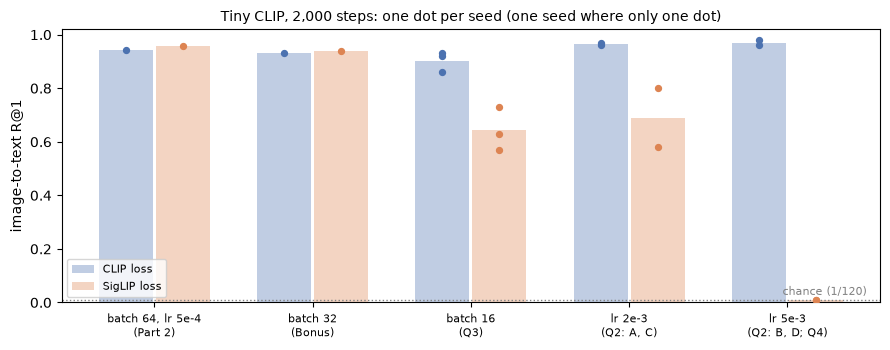

In [6]:
quiz.plot_runs();

<details>
<summary>Help - how should I read this figure?</summary>

Every run behind Q2–Q4 is shown here, together with your two Part 2 runs and the batch-32 runs from the Bonus. Bars are seed means and dots are single seeds. Read
across: the CLIP loss (blue) holds above 0.85 everywhere, and the SigLIP loss (orange) holds only near the settings you trained with (batch 32 or more, learning rate 5e-4). The spread of the orange dots grows
as you move away from those settings.

</details>


## What this quiz tested

- **Softmax scores are relative to the candidate list, and sigmoid scores are not** (Q1). That's why a SigLIP model can abstain.
- **The softmax loss has slack that the sigmoid loss lacks** (Q2). A whole row can shift for free, so large steps hurt the sigmoid loss first.
- **The sigmoid loss fails in a specific way** (Q4). It fails to the constant solution at 5.151, a number you derived from a control.
- **A paper's claim belongs to its regime** (Q3). In this tiny world the sigmoid loss is the one that suffers at small batches. When your runs and a paper disagree,
  the disagreement is the interesting part.


## Try it yourself - reproduce one result

Pick the question you got most wrong and reproduce it. Q4 is the cheapest: one SigLIP run at 10× the learning rate takes 10–40 seconds.

In [ ]:
m = fresh_model(siglip=True)
hist = train_tiny_clip(m, train_images, CAPTION_IDS, train_classes, "siglip", "paired", lr=5e-3, seed=0)
r = evaluate_tiny(m, test_images, CAPTION_IDS, held_out_mask)
print(f"final loss {np.mean(hist['loss'][-50:]):.3f}   i2t R@1 {r['i2t']:.3f}")  # does it land on 5.151?

> 🛠 This cell was not run in the prototype. It needs the lesson's own functions.


## The runs behind this quiz

Every number in the reveals above comes from this cell, which reruns all 14 runs, about 2–10 minutes in total. You don't need to run it. It's here so that you can
check any answer, and so that the quiz can never drift from the code.

In [ ]:
quiz_runs = [("clip", 64, 2e-3, 2), ("clip", 64, 5e-3, 2), ("siglip", 64, 2e-3, 2), ("siglip", 64, 5e-3, 2),
             ("clip", 16, 5e-4, 3), ("siglip", 16, 5e-4, 3)]  # (loss, batch size, learning rate, seeds)
for loss_name, batch_size, lr, n_seeds in quiz_runs:
    for seed in range(n_seeds):
        m = fresh_model(seed, siglip=(loss_name == "siglip"))
        hist = train_tiny_clip(m, train_images, CAPTION_IDS, train_classes, loss_name, "paired",
                               batch_size=batch_size, lr=lr, seed=seed)
        r = evaluate_tiny(m, test_images, CAPTION_IDS, held_out_mask)
        print(f"{loss_name:<7} batch {batch_size:<3} lr {lr:.0e} seed {seed}   "
              f"final loss {np.mean(hist['loss'][-50:]):.3f}   i2t R@1 {r['i2t']:.3f}")

> 🛠 Not run in the prototype. The revealed numbers were copied from 12.1's Bonus text, which reports the lesson author's exploratory runs. Those runs aren't code
> in the course today. The Bonus also doesn't say which learning rate its batch-size sweep used, and this cell is what would pin that down (decision HQ3 in the README).

---

## 🛠 Alternatives to compare, shown on Q3

**Variant A: no code, dropdowns only.** The answer cell is a markdown cell the learner types into, such as `Q3: d, because the paper says sigmoid wins at small
batch`. There's no `quiz.score`, and each Reveal shows the right interval with a line saying "half credit if you chose b". This is closest to ARENA's Solution
dropdowns. It works the same on the website and in Colab, but the learner adds up their own score and nothing checks their ranking pairs.

**Variant C: a live reveal.** After the answer cell, the learner runs one cell per question that trains the held-out runs there and then. For Q3 that's 6 runs, about
1–4 minutes, and the Reveal dropdown only holds the debrief. It's the most convincing ("these numbers came from my machine"), but it's slow, and in lessons with real
models it's impossible: 11.1 needs 13.6 GiB, and 14.2's runs take hours.

**Recommended, the version above (B):** one code cell of answers, a local scorer and pre-written reveals. The key runs are the last cell, so every fresh-kernel run
regenerates them. Cheap questions like Q1 reveal live.